In [1]:
# Error analysis of the three Task A models on both test sets, using their saved predictions (no training).
# Descriptive only: nothing here changes models, thresholds or labels, and no prompt text is displayed.
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import transformers
from transformers import AutoTokenizer

# Find the repository root (works from any folder) and import the shared project code.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/task_a").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from task_a.cue_audit import CUES, review_priority

C:\Users\ONYX\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load dataset v2 and the latest saved test predictions of each model (one column of 0/1 predictions per model).
df = pd.read_parquet(ROOT / "data/processed/binary_jailbreak_v2/combined.parquet",
                     columns=["example_id", "text", "label", "split", "source_dataset", "review_status"])
test = df[df["split"].isin(["test_official", "test_jailbreakhub"])].set_index("example_id")
model_folders = {"LogReg": "results/task_a_binary_tfidf_v2", "SVM": "results/task_a_binary_tfidf_linear_svm_v2",
                 "DistilBERT": "results/task_a_binary_distilbert_v2", "DistilBERT-512": "results/task_a_binary_distilbert_512_v2"}
models = list(model_folders)
for model, folder in model_folders.items():
    prediction_file = sorted((ROOT / folder).glob("run_*/predictions.csv"))[-1]
    saved = pd.read_csv(prediction_file).set_index("example_id")
    test[model] = saved["pred"]
    assert (saved.loc[test.index, "gold"] == test["label"]).all(), f"{model} gold labels differ from the dataset"
    print(f"{model}: {prediction_file.parent.name}")
assert test[models].notna().all().all(), "a test prompt has no saved prediction"

LogReg: run_20261021T022858Z
SVM: run_20261021T022904Z
DistilBERT: run_20261021T024649Z
DistilBERT-512: run_20261021T231957Z


In [3]:
# Figure setup: shared colors and model names (src/task_a/plotting.py) and the saved metrics.json of the same runs
# whose predictions were loaded above. Every chart below is drawn from these saved files only (no model is rerun).
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
from task_a.plotting import ERROR_COLOR, MODEL_COLORS, MODEL_LABELS, SEQUENTIAL, TEXT_SECONDARY, apply_style

apply_style()
run_dirs = {model: sorted((ROOT / folder).glob("run_*/predictions.csv"))[-1].parent for model, folder in model_folders.items()}
saved_metrics = {model: json.loads((run_dir / "metrics.json").read_text(encoding="utf-8")) for model, run_dir in run_dirs.items()}

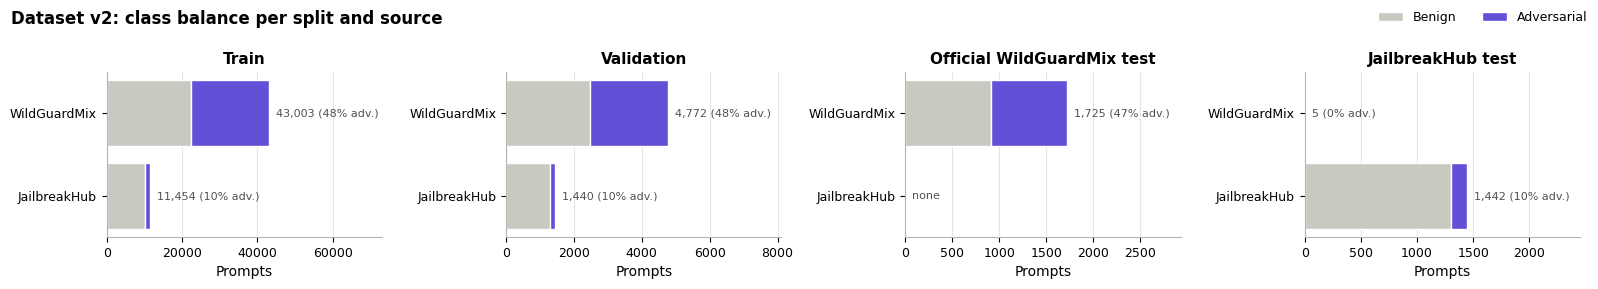

In [4]:
# Dataset overview (dataset v2, every split): benign and adversarial prompts per split and source.
# Each panel has its own count scale, because train is about 25 times larger than either test set.
split_titles = {"train": "Train", "validation": "Validation", "test_official": "Official WildGuardMix test",
                "test_jailbreakhub": "JailbreakHub test"}
source_titles = {"wildguardmix": "WildGuardMix", "jailbreakhub": "JailbreakHub"}
class_counts = pd.crosstab([df["split"], df["source_dataset"]], df["label"])
fig, axes = plt.subplots(1, 4, figsize=(16, 2.9))
for ax, (split, title) in zip(axes, split_titles.items()):
    part = class_counts.loc[split].reindex(list(source_titles), fill_value=0)
    rows = np.arange(len(part))[::-1]
    ax.barh(rows, part[0], color="#c9c8c1", edgecolor="white", label="Benign")
    ax.barh(rows, part[1], left=part[0], color="#6250d6", edgecolor="white", label="Adversarial")
    for row, (benign_n, attack_n) in zip(rows, zip(part[0], part[1])):
        total = benign_n + attack_n
        ax.text(total, row, f"  {total:,} ({attack_n / total:.0%} adv.)" if total else "  none", va="center", fontsize=8,
                color=TEXT_SECONDARY)
    ax.set_yticks(rows, list(source_titles.values()))
    ax.set_xlim(0, part.sum(axis=1).max() * 1.7)
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel("Prompts")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.suptitle("Dataset v2: class balance per split and source", x=0.01, ha="left")
fig.tight_layout()

**Figure: class balance of dataset v2 (all splits, counts only).** WildGuardMix is roughly balanced (47–48% adversarial) in every split, while JailbreakHub is about 10% adversarial. The official test contains only WildGuardMix prompts. The JailbreakHub test contains 1,442 JailbreakHub prompts and 5 benign WildGuardMix prompts; the saved JailbreakHub-test metrics include all 1,447. With 1,306 benign prompts against 141 attacks there, a 1% false-positive rate is about 13 flagged benign prompts. That is why adversarial precision on this test set reacts strongly to small changes in FPR.

In [5]:
# Error counts per model and test set: missed attacks (false negatives) and benign prompts flagged (false positives).
split_names = {"test_official": "Official WildGuardMix test", "test_jailbreakhub": "JailbreakHub test"}
counts = {}
for split, name in split_names.items():
    part = test[test["split"] == split]
    for model in models:
        counts[(name, model)] = {"Attacks": (part["label"] == 1).sum(), "Missed attacks": ((part["label"] == 1) & (part[model] == 0)).sum(),
                                 "Benign": (part["label"] == 0).sum(), "Benign flagged": ((part["label"] == 0) & (part[model] == 1)).sum()}
pd.DataFrame(counts).T

Attacks  Missed attacks  Benign  \
Official WildGuardMix test LogReg              810               3     915   
                           SVM                 810               2     915   
                           DistilBERT          810               3     915   
                           DistilBERT-512      810               2     915   
JailbreakHub test          LogReg              141              47    1306   
                           SVM                 141              43    1306   
                           DistilBERT          141              65    1306   
                           DistilBERT-512      141              55    1306   

                                           Benign flagged  
Official WildGuardMix test LogReg                       8  
                           SVM                          6  
                           DistilBERT                   1  
                           DistilBERT-512               1  
JailbreakHub test          LogReg                      64  
                           SVM                         51  
                           DistilBERT                  16  
                           DistilBERT-512              31

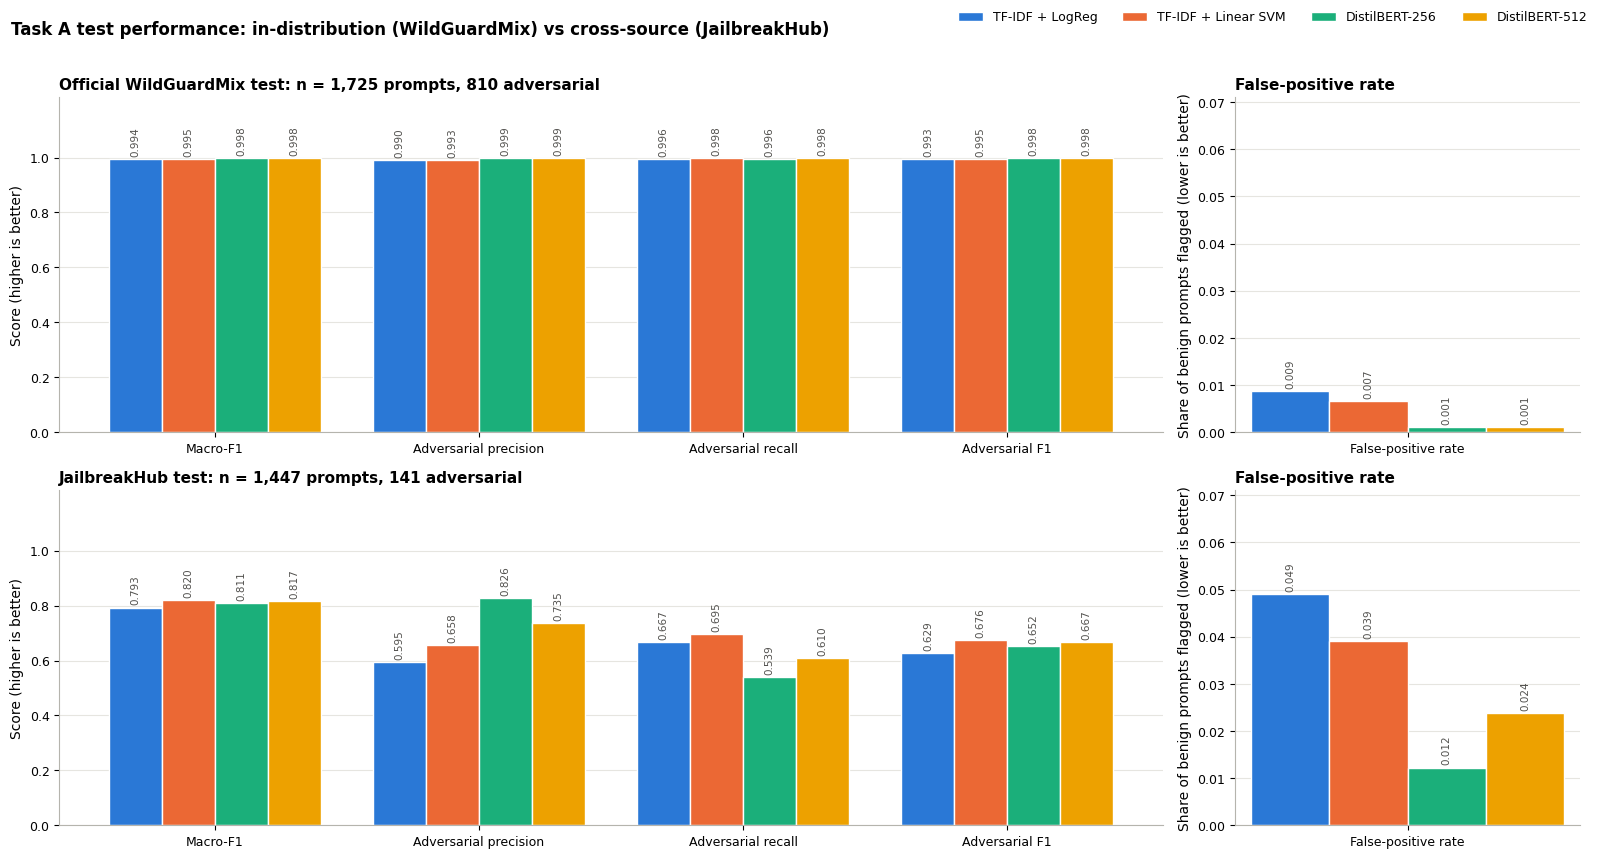

In [6]:
# Performance per test set from each run's saved metrics.json (default thresholds; ADVERSARIAL is the positive class).
# Quality scores share one 0-1 axis in both rows; FPR gets its own axis (shared by both rows) because its values are small.
quality = {"Macro-F1": lambda m: m["macro_f1"], "Adversarial precision": lambda m: m["per_class"]["ADVERSARIAL"]["precision"],
           "Adversarial recall": lambda m: m["per_class"]["ADVERSARIAL"]["recall"],
           "Adversarial F1": lambda m: m["per_class"]["ADVERSARIAL"]["f1"]}
performance = pd.DataFrame({(split_names[split], model): {**{name: get(saved_metrics[model][split]["all"]) for name, get in quality.items()},
                                                          "FPR": saved_metrics[model][split]["all"]["fpr"]}
                            for split in split_names for model in models}).T.astype(float)
assert performance.notna().all().all(), "a saved metric is undefined (None); it would be shown as a missing bar"
width = 0.8 / len(models)
fig, axes = plt.subplots(2, 2, figsize=(16, 8.6), gridspec_kw={"width_ratios": [4, 1.25]})
for row, (split, name) in enumerate(split_names.items()):
    reference = saved_metrics[models[0]][split]["all"]
    for ax, metric_names, top in [(axes[row, 0], list(quality), 1.22), (axes[row, 1], ["FPR"], performance["FPR"].max() * 1.45)]:
        x = np.arange(len(metric_names))
        for i, model in enumerate(models):
            bars = ax.bar(x + (i - (len(models) - 1) / 2) * width, performance.loc[(name, model), metric_names], width,
                          color=MODEL_COLORS[model], edgecolor="white", linewidth=1, label=MODEL_LABELS[model])
            ax.bar_label(bars, fmt="%.3f", rotation=90, padding=2, fontsize=7.5, color=TEXT_SECONDARY)
        ax.set_xticks(x, metric_names if len(metric_names) > 1 else ["False-positive rate"])
        ax.set_ylim(0, top)
    axes[row, 0].set_yticks(np.linspace(0, 1, 6))
    axes[row, 0].set_ylabel("Score (higher is better)")
    axes[row, 1].set_ylabel("Share of benign prompts flagged (lower is better)")
    axes[row, 0].set_title(f"{name}: n = {reference['n']:,} prompts, "
                           f"{reference['per_class']['ADVERSARIAL']['support']:,} adversarial", loc="left")
    axes[row, 1].set_title("False-positive rate", loc="left")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=len(models))
fig.suptitle("Task A test performance: in-distribution (WildGuardMix) vs cross-source (JailbreakHub)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))

**Figure: test performance per model (saved `metrics.json`, default thresholds, positive class = ADVERSARIAL).** On the official WildGuardMix test all four models are near ceiling (macro-F1 0.994–0.998, FPR ≤ 0.009). Their differences come from 3–11 errors out of 1,725 prompts, so this test cannot separate the models. On the JailbreakHub test every score drops and the models diverge:

- **TF-IDF + Linear SVM:** highest adversarial recall (0.695), adversarial F1 (0.676) and macro-F1 (0.820).
- **DistilBERT-256:** highest precision (0.826) and lowest FPR (0.012), but lowest recall (0.539).
- **DistilBERT-512:** between the two on both.

These are single runs at default thresholds, so macro-F1 differences of a few hundredths do not show that one model is better.

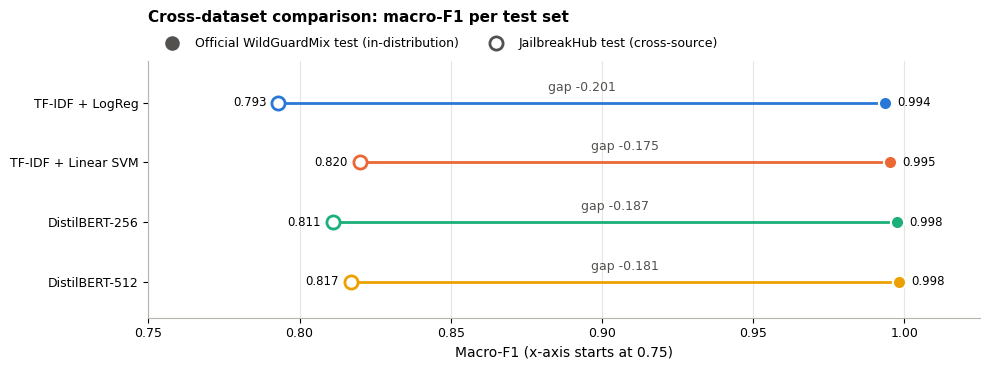

In [7]:
# Cross-dataset comparison: macro-F1 on the official WildGuardMix test vs the JailbreakHub test, per model (same runs,
# default thresholds). Dots, not bars, so the x-axis can start at 0.75 without exaggerating bar lengths.
fig, ax = plt.subplots(figsize=(10, 3.8))
rows = np.arange(len(models))[::-1]
for row, model in zip(rows, models):
    in_source = performance.loc[(split_names["test_official"], model), "Macro-F1"]
    cross_source = performance.loc[(split_names["test_jailbreakhub"], model), "Macro-F1"]
    ax.plot([cross_source, in_source], [row, row], color=MODEL_COLORS[model], linewidth=2, zorder=1)
    ax.scatter(in_source, row, s=90, color=MODEL_COLORS[model], edgecolor="white", linewidth=1.5, zorder=2)
    ax.scatter(cross_source, row, s=90, facecolor="white", edgecolor=MODEL_COLORS[model], linewidth=2, zorder=2)
    ax.text((in_source + cross_source) / 2, row + 0.2, f"gap {cross_source - in_source:+.3f}", ha="center", fontsize=9,
            color=TEXT_SECONDARY)
    ax.text(cross_source - 0.004, row, f"{cross_source:.3f}", ha="right", va="center", fontsize=8.5)
    ax.text(in_source + 0.004, row, f"{in_source:.3f}", ha="left", va="center", fontsize=8.5)
ax.scatter([], [], s=90, color="#52514e", label="Official WildGuardMix test (in-distribution)")
ax.scatter([], [], s=90, facecolor="white", edgecolor="#52514e", linewidth=2, label="JailbreakHub test (cross-source)")
ax.set_yticks(rows, [MODEL_LABELS[model] for model in models])
ax.set_ylim(-0.6, len(models) - 0.3)
ax.set_xlim(0.75, 1.025)
ax.set_xticks(np.arange(0.75, 1.001, 0.05))
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Macro-F1 (x-axis starts at 0.75)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax.set_title("Cross-dataset comparison: macro-F1 per test set", loc="left", pad=28)
fig.tight_layout()

**Figure: cross-dataset comparison of macro-F1 (official WildGuardMix test vs JailbreakHub test).** Every model loses 0.175–0.201 macro-F1 between the two test sets. DistilBERT's small lead on the official test does not carry over: on JailbreakHub the four models are within 0.03 of each other.

This figure shows the size of the gap, not its cause. The two test sets differ in source, class balance (47% vs 10% adversarial), prompt length and label provenance: JailbreakHub labels include reviewed corrections that are not human-verified. The experiment does not separate these factors. JailbreakHub prompts also appear in training, so this is a cross-source comparison, not a test on a fully unseen domain.

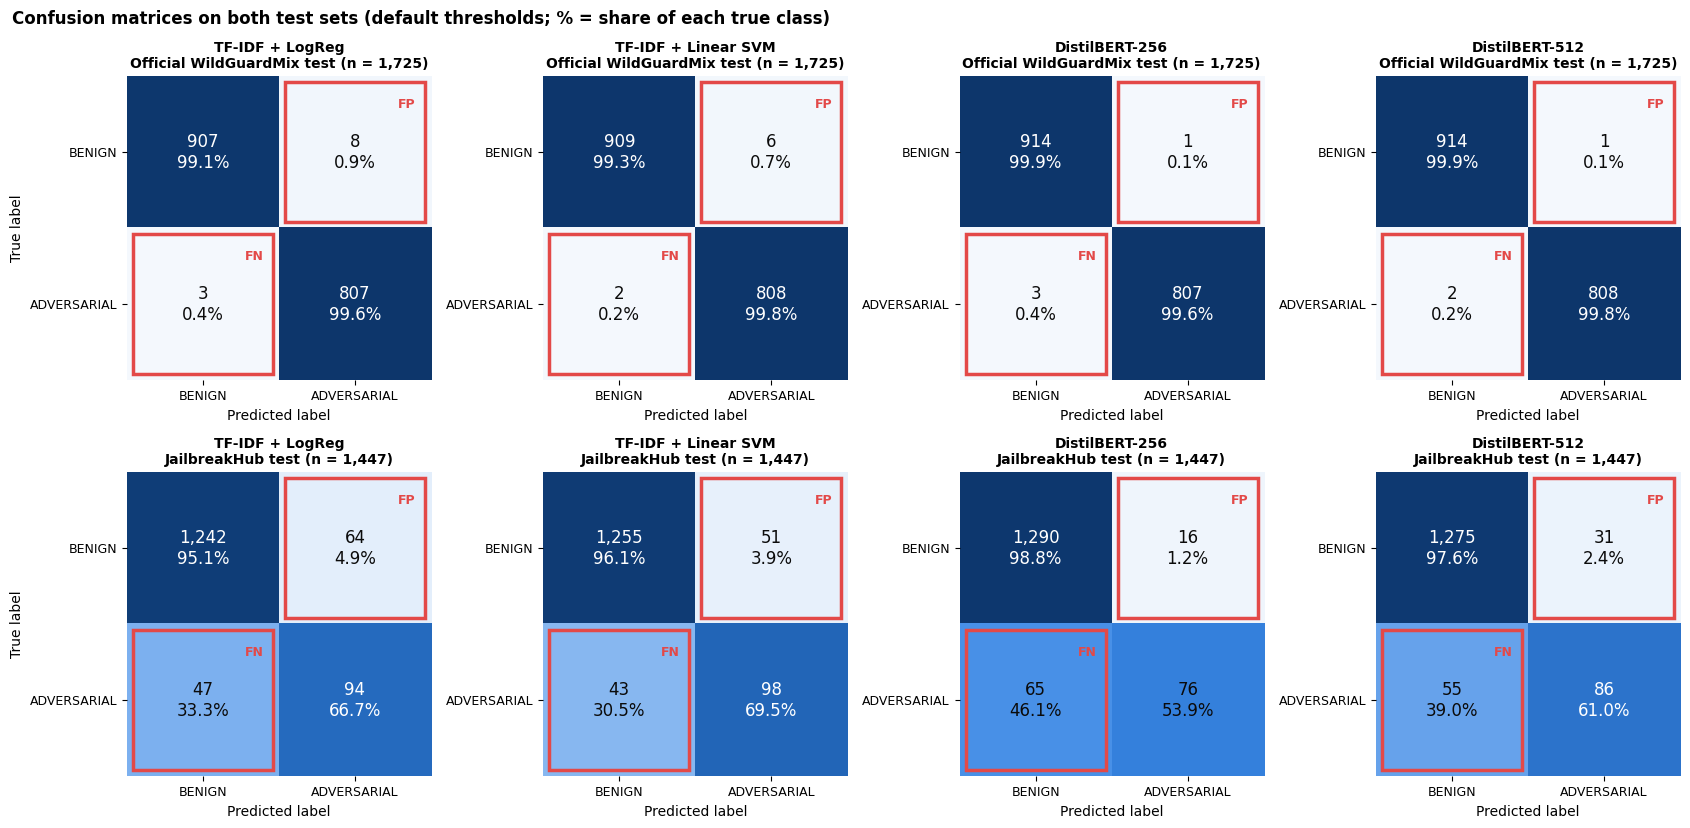

In [8]:
# Confusion matrices from the saved predictions (rows = true label, columns = prediction), checked against metrics.json.
# Shade = share of the true class; red outlines mark errors: FN = attacks missed, FP = benign prompts flagged.
class_names = ["BENIGN", "ADVERSARIAL"]
fig, axes = plt.subplots(2, len(models), figsize=(17, 8.4))
for row, (split, name) in enumerate(split_names.items()):
    part = test[test["split"] == split]
    for col, model in enumerate(models):
        ax = axes[row, col]
        matrix = pd.crosstab(part["label"], part[model]).reindex(index=[0, 1], columns=[0, 1], fill_value=0).to_numpy()
        cm = saved_metrics[model][split]["all"]["confusion_matrix"]
        assert matrix.tolist() == [[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]], f"{model} {split}: predictions and metrics.json disagree"
        shares = matrix / matrix.sum(axis=1, keepdims=True)
        ax.imshow(shares, cmap=SEQUENTIAL, vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{matrix[i, j]:,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=12,
                        color="white" if shares[i, j] > 0.55 else "#0b0b0b")
        for (i, j), tag in {(1, 0): "FN", (0, 1): "FP"}.items():
            ax.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, fill=False, edgecolor=ERROR_COLOR, linewidth=2.5))
            ax.text(j + 0.4, i - 0.36, tag, ha="right", va="top", fontsize=9, fontweight="bold", color=ERROR_COLOR)
        ax.set_xticks([0, 1], class_names)
        ax.set_yticks([0, 1], class_names)
        ax.grid(False)
        ax.spines[:].set_visible(False)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label" if col == 0 else "")
        ax.set_title(f"{MODEL_LABELS[model]}\n{name} (n = {len(part):,})", fontsize=10)
fig.suptitle("Confusion matrices on both test sets (default thresholds; % = share of each true class)", x=0.01, ha="left")
fig.tight_layout()

**Figure: confusion matrices (saved predictions, checked against `metrics.json`; red outlines = errors).**

- **Official WildGuardMix test:** at most 8 false positives and 3 false negatives per model.
- **JailbreakHub test, as rates:** misses dominate. From 30.5% (Linear SVM) to 46.1% (DistilBERT-256) of attacks are missed, while only 1.2–4.9% of benign prompts are flagged.
- **JailbreakHub test, as counts:** the TF-IDF models make more false positives (64 and 51) than false negatives (47 and 43), because benign prompts outnumber attacks about 9 to 1.
- **256 vs 512 tokens:** DistilBERT-512 misses 10 fewer attacks than DistilBERT-256 but flags 15 more benign prompts.

In [9]:
# How many of the four models got each prompt wrong: errors shared by all of them are the hardest cases.
test["models_wrong"] = test[models].ne(test["label"], axis=0).sum(axis=1)
pd.crosstab([test["split"], test["label"].map({0: "Benign", 1: "Attack"})], test["models_wrong"]).rename(columns=lambda n: f"wrong by {n}")

models_wrong              wrong by 0  wrong by 1  wrong by 2  wrong by 3  \
split             label                                                    
test_jailbreakhub Attack          68          15          15           7   
                  Benign        1222          32          35           8   
test_official     Attack         805           1           3           1   
                  Benign         907           2           5           0   

models_wrong              wrong by 4  
split             label               
test_jailbreakhub Attack          36  
                  Benign           9  
test_official     Attack           0  
                  Benign           1

In [10]:
# Prompt features: DistilBERT token count (including [CLS]/[SEP]) and whether it is cut at 256 tokens.
transformers.logging.set_verbosity_error()  # silence the "longer than 512" notice: we only count tokens here
tokenizer = AutoTokenizer.from_pretrained(sorted((ROOT / model_folders["DistilBERT"]).glob("run_*/model"))[-1])
test["tokens"] = [len(ids) for ids in tokenizer(test["text"].tolist(), truncation=False)["input_ids"]]
test["over_256"] = test["tokens"] > 256

In [11]:
# Position of the first strong jailbreak cue (cue_audit patterns, AIPRM templates excluded), in tokens.
# With 256-token inputs, a cue starting at token 255 or later is cut off before DistilBERT sees it.
def first_strong_cue_token(text):
    _, strong_categories, _ = review_priority(text)
    starts = [CUES[category][0].search(text).start() for category in strong_categories]
    return len(tokenizer(text[:min(starts)])["input_ids"]) - 1 if starts else np.nan  # tokens before the cue

test["first_cue_token"] = test["text"].map(first_strong_cue_token)
test["cue_after_cutoff"] = test["first_cue_token"] >= 255

In [12]:
# Familiarity: TF-IDF cosine similarity to the closest training prompt (baseline TF-IDF settings).
# A low value means the prompt is worded unlike anything in training, e.g. an unfamiliar attack formulation.
train_text = df.loc[df["split"] == "train", "text"]
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train_text)
train_matrix, test_matrix = vectorizer.transform(train_text), vectorizer.transform(test["text"])
closest = []
for start in range(0, test_matrix.shape[0], 500):  # in chunks to limit memory
    closest.append((test_matrix[start:start + 500] @ train_matrix.T).max(axis=1).toarray().ravel())
test["closest_train_similarity"] = np.concatenate(closest)

In [13]:
# Profile of a group of prompts, used in the next three tables.
def profile(group):
    return {"Prompts": len(group), "Median tokens": group["tokens"].median(), "Over 256 tokens": group["over_256"].mean(),
            "No strong cue": group["first_cue_token"].isna().mean(), "Cue after token 255": group["cue_after_cutoff"].mean(),
            "Median similarity to training": group["closest_train_similarity"].median()}

table_format = {"Prompts": "{:,.0f}", "Median tokens": "{:,.0f}", "Over 256 tokens": "{:.0%}", "No strong cue": "{:.0%}",
                "Cue after token 255": "{:.0%}", "Median similarity to training": "{:.2f}"}

In [14]:
# JailbreakHub attacks: are the missed ones longer, cut at 256, cue-late, or less similar to training prompts?
jbh_attacks = test[(test["split"] == "test_jailbreakhub") & (test["label"] == 1)]
attack_profile = pd.DataFrame({(model, outcome): profile(jbh_attacks[jbh_attacks[model] == prediction])
                               for model in models for outcome, prediction in [("missed", 0), ("caught", 1)]}).T
attack_profile.style.format(table_format)

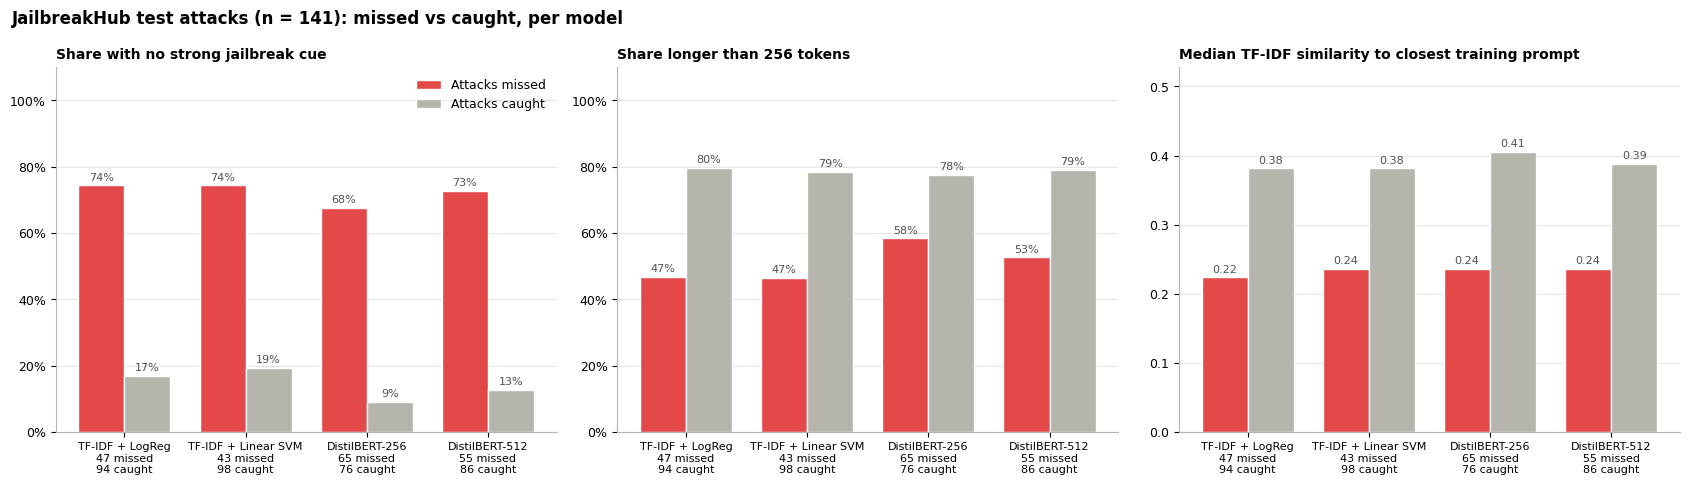

In [15]:
# Missed vs caught JailbreakHub attacks per model, drawn from the profile table above (same features, no new categories).
# The first two panels are shares of prompts; the third is a median similarity, so it has its own axis.
panels = {"No strong cue": ("Share with no strong jailbreak cue", True), "Over 256 tokens": ("Share longer than 256 tokens", True),
          "Median similarity to training": ("Median TF-IDF similarity to closest training prompt", False)}
outcome_colors = {"missed": ERROR_COLOR, "caught": "#b5b4ad"}
x = np.arange(len(models))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
for ax, (column, (title, is_share)) in zip(axes, panels.items()):
    for k, outcome in enumerate(outcome_colors):
        values = [attack_profile.loc[(model, outcome), column] for model in models]
        bars = ax.bar(x + (k - 0.5) * 0.38, values, 0.38, color=outcome_colors[outcome], edgecolor="white",
                      label=f"Attacks {outcome}")
        ax.bar_label(bars, fmt="{:.0%}" if is_share else "{:.2f}", padding=2, fontsize=8, color=TEXT_SECONDARY)
    ax.set_xticks(x, [f"{MODEL_LABELS[m]}\n{attack_profile.loc[(m, 'missed'), 'Prompts']:.0f} missed\n"
                      f"{attack_profile.loc[(m, 'caught'), 'Prompts']:.0f} caught" for m in models], fontsize=8)
    ax.set_ylim(0, 1.1 if is_share else attack_profile[column].max() * 1.3)
    if is_share:
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(title, loc="left", fontsize=10)
axes[0].legend(loc="upper right")
fig.suptitle(f"JailbreakHub test attacks (n = {len(jbh_attacks)}): missed vs caught, per model", x=0.01, ha="left")
fig.tight_layout()

**Figure: missed vs caught JailbreakHub test attacks (features from the profile table above).** For every model, compared with caught attacks, missed attacks:

- more often contain no strong jailbreak cue (68–74% vs 9–19%);
- are less often longer than 256 tokens (47–58% vs 78–80%);
- are less similar to their closest training prompt (median 0.22–0.24 vs 0.38–0.41).

Missed attacks tend to be shorter than caught ones, so this table gives no sign that truncation drives the misses. These are associations within 141 attacks in one test set, not causes. "Strong cue" is a regular-expression proxy (`src/task_a/cue_audit.py`), not a reviewed label.

In [16]:
# JailbreakHub benign prompts: how do wrongly flagged ones differ from correctly passed ones?
jbh_benign = test[(test["split"] == "test_jailbreakhub") & (test["label"] == 0)]
benign_profile = pd.DataFrame({(model, outcome): profile(jbh_benign[jbh_benign[model] == prediction])
                               for model in models for outcome, prediction in [("flagged", 1), ("passed", 0)]}).T
benign_profile.style.format(table_format)

In [17]:
# Differences between the two test sources, per label (all prompts, regardless of model errors).
source_profile = pd.DataFrame({(split_names[split], "Attack" if label else "Benign"): profile(group)
                               for (split, label), group in test.groupby(["split", "label"])}).T
source_profile.style.format(table_format)

In [18]:
# RQ2 hard-negative slice: benign test prompts that contain jailbreak vocabulary (a strong cue) but are labelled
# benign. A proxy for hard negatives, not a curated set; false-positive rate per model, with slice sizes.
benign = test[test["label"] == 0].assign(has_cue=lambda f: f["first_cue_token"].notna())
hard_negatives = {}
for (split, has_cue), group in benign.groupby(["split", "has_cue"]):
    row = {"Prompts": len(group)}
    for model in models:
        row[f"{model} FPR"] = (group[model] == 1).mean()
    hard_negatives[(split_names[split], "with jailbreak cue" if has_cue else "no cue")] = row
pd.DataFrame(hard_negatives).T.style.format({"Prompts": "{:,.0f}", **{f"{m} FPR": "{:.3f}" for m in models}})

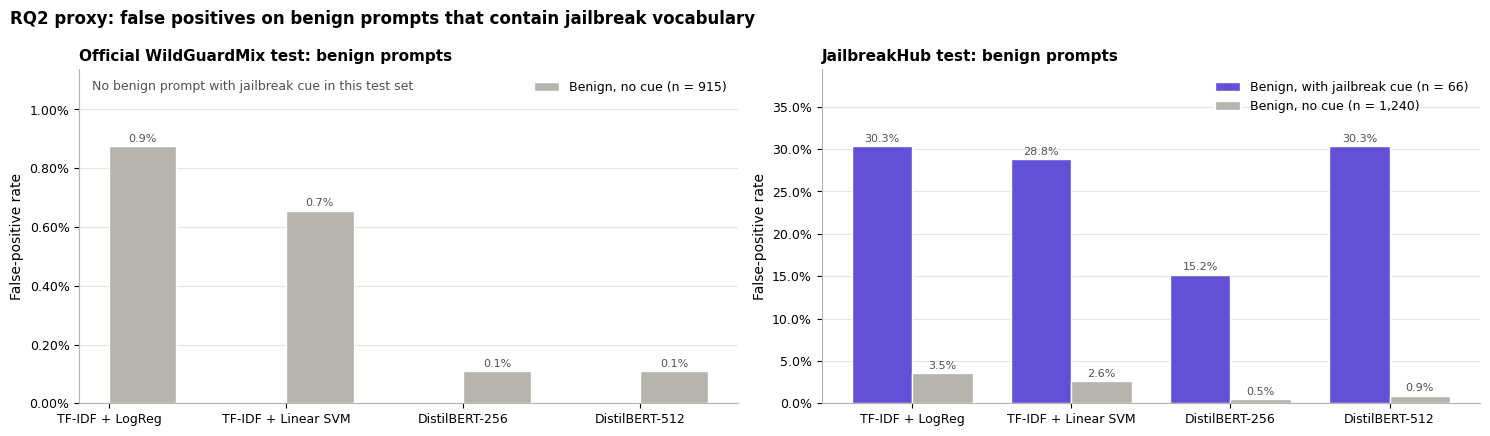

In [19]:
# RQ2 proxy slice as a chart: false-positive rate on benign test prompts with vs without a strong jailbreak cue.
# Slice sizes are in each legend; the panels have their own scales, and a small slice gives a noisy rate.
hard_negative_table = pd.DataFrame(hard_negatives).T
slice_colors = {"with jailbreak cue": "#6250d6", "no cue": "#b5b4ad"}
x = np.arange(len(models))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, name in zip(axes, split_names.values()):
    for k, (slice_name, color) in enumerate(slice_colors.items()):
        if (name, slice_name) not in hard_negative_table.index:
            ax.text(0.02, 0.97, f"No benign prompt {slice_name} in this test set", transform=ax.transAxes, va="top",
                    fontsize=9, color=TEXT_SECONDARY)
            continue
        slice_row = hard_negative_table.loc[(name, slice_name)]
        bars = ax.bar(x + (k - 0.5) * 0.38, [slice_row[f"{m} FPR"] for m in models], 0.38, color=color, edgecolor="white",
                      label=f"Benign, {slice_name} (n = {slice_row['Prompts']:,.0f})")
        ax.bar_label(bars, fmt="{:.1%}", padding=2, fontsize=8, color=TEXT_SECONDARY)
    ax.set_xticks(x, [MODEL_LABELS[m] for m in models], fontsize=9)
    ax.set_ylim(0, hard_negative_table.loc[name, [f"{m} FPR" for m in models]].to_numpy().max() * 1.3)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel("False-positive rate")
    ax.set_title(f"{name}: benign prompts", loc="left")
    ax.legend(loc="upper right")
fig.suptitle("RQ2 proxy: false positives on benign prompts that contain jailbreak vocabulary", x=0.01, ha="left")
fig.tight_layout()

**Figure: RQ2 proxy, false-positive rate on benign prompts with vs without jailbreak vocabulary.** On the JailbreakHub test, models flag benign prompts that contain a strong jailbreak cue far more often (15.2–30.3%) than benign prompts without one (0.5–3.5%). DistilBERT-256 has the lowest rate on this slice, and DistilBERT-512 flags as many as TF-IDF + LogReg (30.3%).

Treat these rates with care:

- The slice has only 66 prompts, so one prompt moves its rate by about 1.5 points.
- The slice is a regular-expression proxy, not a curated hard-negative set.
- The official WildGuardMix test has no benign prompt with a strong cue, so its panel shows only the no-cue rates.

In [20]:
# RQ3 unseen-formulation proxy: attack recall by similarity to the closest training prompt, in fixed bins chosen
# before looking at results (low < 0.2, medium 0.2-0.4, high >= 0.4). Test prompts are never used for tuning.
attacks = test[test["label"] == 1].assign(similarity_bin=lambda f: pd.cut(f["closest_train_similarity"], [-0.01, 0.2, 0.4, 1.01],
                                                                         labels=["low (<0.2)", "medium (0.2-0.4)", "high (>=0.4)"]))
unseen = {}
for (split, similarity_bin), group in attacks.groupby(["split", "similarity_bin"], observed=True):
    row = {"Attacks": len(group)}
    for model in models:
        row[f"{model} recall"] = (group[model] == 1).mean()
    unseen[(split_names[split], similarity_bin)] = row
pd.DataFrame(unseen).T.style.format({"Attacks": "{:,.0f}", **{f"{m} recall": "{:.3f}" for m in models}})

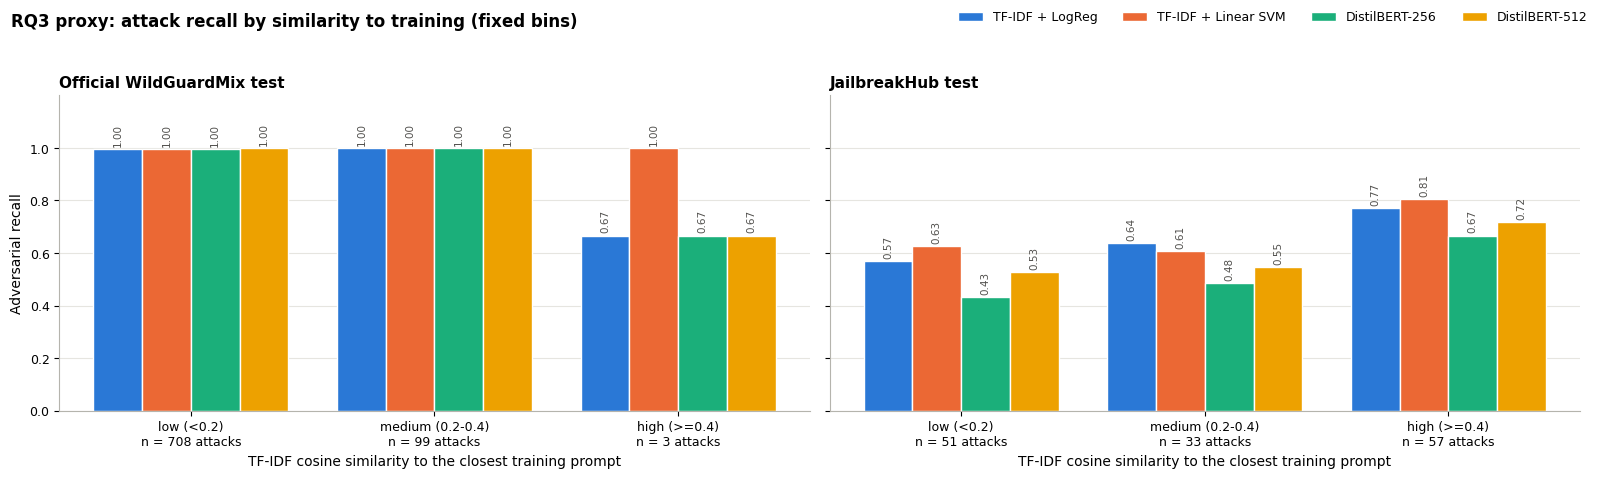

In [21]:
# RQ3 proxy slice as a chart: attack recall in the fixed similarity bins of the table above, per model and test set.
unseen_table = pd.DataFrame(unseen).T
width = 0.8 / len(models)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, name in zip(axes, split_names.values()):
    part = unseen_table.loc[name]
    bins = np.arange(len(part))
    for i, model in enumerate(models):
        bars = ax.bar(bins + (i - (len(models) - 1) / 2) * width, part[f"{model} recall"], width, color=MODEL_COLORS[model],
                      edgecolor="white", linewidth=1, label=MODEL_LABELS[model])
        ax.bar_label(bars, fmt="%.2f", rotation=90, padding=2, fontsize=7.5, color=TEXT_SECONDARY)
    ax.set_xticks(bins, [f"{similarity_bin}\nn = {n:.0f} attacks" for similarity_bin, n in zip(part.index, part["Attacks"])])
    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_xlabel("TF-IDF cosine similarity to the closest training prompt")
    ax.set_title(name, loc="left")
axes[0].set_ylabel("Adversarial recall")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=len(models))
fig.suptitle("RQ3 proxy: attack recall by similarity to training (fixed bins)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))

**Figure: RQ3 proxy, attack recall by TF-IDF similarity to the closest training prompt (fixed bins).** On the JailbreakHub test, every model has higher recall in the high-similarity bin (0.67–0.81) than in the low bin (0.43–0.63). The medium bin does not follow a consistent order. One reading is that the detectors rely partly on familiar wording, but this analysis does not test that.

On the official test, recall is about 1.0 even in the low bin (708 attacks), so low lexical similarity alone does not produce misses there. The official high bin holds only 3 attacks, and the JailbreakHub bins hold 33–57, so differences under about 0.1 are within noise. TF-IDF similarity measures word overlap, not meaning: this is a proxy for unseen formulations, not a held-out-category test.

In [22]:
# Every official-test error (few), features only: which models erred and the prompt profile.
official_errors = test[(test["split"] == "test_official") & (test["models_wrong"] > 0)]
official_errors[["label", *models, "tokens", "first_cue_token", "closest_train_similarity"]].sort_values("label")

,label,LogReg,SVM,DistilBERT,DistilBERT-512,tokens,first_cue_token,closest_train_similarity
example_id,,,,,,,,
wildguard:test:167,0,1,1,0,0,65,NaN,0.143150
wildguard:test:210,0,1,0,0,0,47,NaN,0.247104
wildguard:test:217,0,1,0,0,0,33,NaN,0.366770
wildguard:test:265,0,1,1,0,0,65,NaN,0.183908
wildguard:test:286,0,1,1,1,1,71,NaN,0.134709
wildguard:test:284,0,1,1,0,0,71,NaN,0.150407
wildguard:test:814,0,1,1,0,0,22,NaN,0.249151
wildguard:test:858,0,1,1,0,0,67,NaN,0.449648
wildguard:test:82,1,0,1,0,0,16,NaN,0.538775


In [23]:
# Label-review candidates (NOT corrections): attacks missed by every model with no strong cue, and benign prompts
# flagged by every model that contain a strong cue. Text goes to a Git-ignored CSV for private reading, not the screen.
candidates = test[((test["label"] == 1) & (test["models_wrong"] == len(models)) & test["first_cue_token"].isna())
                  | ((test["label"] == 0) & (test["models_wrong"] == len(models)) & test["first_cue_token"].notna())]
out_dir = ROOT / "results/error_analysis" / datetime.now(timezone.utc).strftime("task_a_v2_%Y%m%dT%H%M%SZ")
out_dir.mkdir(parents=True, exist_ok=False)
candidates.reset_index()[["example_id", "split", "label", "review_status", "tokens", "first_cue_token",
                          "closest_train_similarity", "text"]].to_csv(out_dir / "label_review_candidates.csv", index=False)
test.drop(columns="text").to_csv(out_dir / "test_error_features.csv")
print(f"{len(candidates)} candidates ({candidates['review_status'].ne('').sum()} already reviewed earlier); "
      f"saved to {out_dir.relative_to(ROOT)}")
pd.crosstab(candidates["split"], candidates["label"].map({0: "Benign flagged by all models", 1: "Attack missed by all models"}))

37 candidates (1 already reviewed earlier); saved to results\error_analysis\task_a_v2_20261022T040723Z


label,Attack missed by all models,Benign flagged by all models
split,,
test_jailbreakhub,30,7


In [24]:
# Summary generated from the tables above. These are associations within one test set, not proven causes.
for model in models:
    missed, caught = attack_profile.loc[(model, "missed")], attack_profile.loc[(model, "caught")]
    print(f"{model}: missed {missed['Prompts']:.0f} JailbreakHub attacks. Missed vs caught: median {missed['Median tokens']:.0f} vs "
          f"{caught['Median tokens']:.0f} tokens, over 256 tokens {missed['Over 256 tokens']:.0%} vs {caught['Over 256 tokens']:.0%}, "
          f"no strong cue {missed['No strong cue']:.0%} vs {caught['No strong cue']:.0%}, "
          f"cue after token 255 {missed['Cue after token 255']:.0%} vs {caught['Cue after token 255']:.0%}, "
          f"similarity to training {missed['Median similarity to training']:.2f} vs {caught['Median similarity to training']:.2f}.")
all_missed = jbh_attacks[jbh_attacks["models_wrong"] == len(models)]
print(f"{len(all_missed)} of {len(jbh_attacks)} JailbreakHub attacks were missed by all models; "
      f"{all_missed['first_cue_token'].isna().mean():.0%} of those contain no strong cue.")
print(f"Benign prompts flagged by all models: {((test['label'] == 0) & (test['models_wrong'] == len(models))).sum()} "
      f"(JailbreakHub {((jbh_benign['models_wrong'] == len(models))).sum()}).")
print("Limitations: cue position is a proxy for where the malicious instruction sits; review candidates may be "
      "correct labels; JailbreakHub labels are partly unreviewed and the 174 corrections are not human-verified.")

LogReg: missed 47 JailbreakHub attacks. Missed vs caught: median 210 vs 504 tokens, over 256 tokens 47% vs 80%, no strong cue 74% vs 17%, cue after token 255 4% vs 10%, similarity to training 0.22 vs 0.38.
SVM: missed 43 JailbreakHub attacks. Missed vs caught: median 192 vs 454 tokens, over 256 tokens 47% vs 79%, no strong cue 74% vs 19%, cue after token 255 5% vs 9%, similarity to training 0.24 vs 0.38.
DistilBERT: missed 65 JailbreakHub attacks. Missed vs caught: median 300 vs 540 tokens, over 256 tokens 58% vs 78%, no strong cue 68% vs 9%, cue after token 255 8% vs 8%, similarity to training 0.24 vs 0.41.
DistilBERT-512: missed 55 JailbreakHub attacks. Missed vs caught: median 294 vs 412 tokens, over 256 tokens 53% vs 79%, no strong cue 73% vs 13%, cue after token 255 11% vs 6%, similarity to training 0.24 vs 0.39.
36 of 141 JailbreakHub attacks were missed by all models; 83% of those contain no strong cue.
Benign prompts flagged by all models: 10 (JailbreakHub 9).
Limitations: cue 